# Lab: Design your own activation function
Implement an activation function for a neural network using only NumPy. Your activation(x) function takes an array of values and returns the activated outputs.

The training harness handles everything else (forward pass, backpropagation, weight updates). You just define how neurons transform their inputs.

You may implement ANY activation function you like: ReLU, sigmoid, tanh, or something creative. Your activation will be used in a simple neural network trained on MNIST.

## Activation functions

### 1. ReLU
Implementing the ReLU activation function:
$$f(x)=\begin{cases}
    x\;\;\;&\text{ if } x \geq 0\\
    0 &\text{ otherwise}
\end{cases} = \max(0,x)$$

Advantages:
- Very simple and computationally efficient
- Often enables faster convergence than sigmoid/tanh
- Produces sparse activations because negative inputs become zero

Disadvantages:
- Dying ReLU: neurons can get stuck outputting zero
- Not differentiable exactly at \(x=0\)
- Outputs are unbounded for positive inputs
- Zero gradient for negative inputs prevents learning in that region

Implementation:

In [ ]:
import numpy as np

def activation(x):
    '''
    Apply an activation function element-wise.
    
    Args:
        x: numpy array of any shape (raw neuron outputs)
    
    Returns:
        numpy array of same shape (activated outputs)
    
    Requirements:
        - Must be non-linear (not just returning x)
        - Must work on arrays of any shape
        - Must be deterministic
    '''
    return np.maximum(0,x)

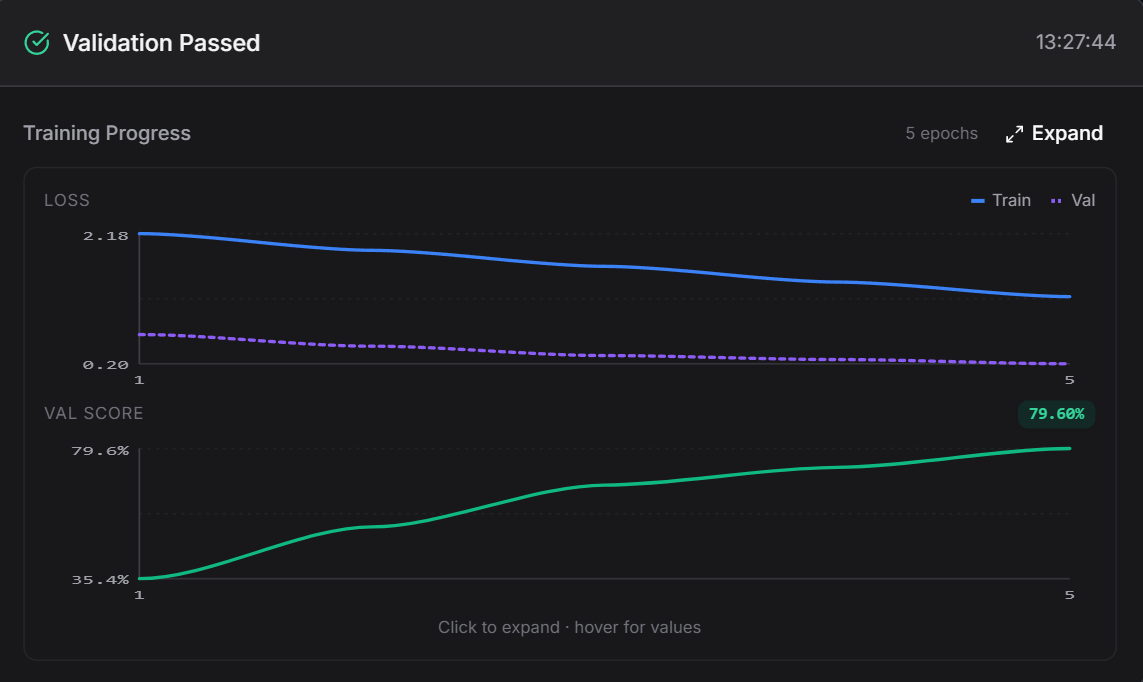

Final Accuracy: 84.3%

### 2. Leaky ReLU
Implementing the Leaky ReLU activation function:
$$f(x)=\begin{cases}
    x\;\;\;&\text{ if } x \geq 0\\
    \alpha x &\text{ otherwise}
\end{cases} = \max(\alpha x,x)$$
where $\alpha\in(0,1)$ is an hyperparameter.

Advantages:
- Reduces the dying ReLU problem
- Keeps a small gradient for negative inputs
- Simple and computationally efficient
- Often trains more reliably than standard ReLU

Disadvantages:
- Requires choosing a negative-slope parameter $\alpha$
- Negative outputs can reduce sparsity
- Still unbounded for large positive inputs

Implementation:

In [ ]:
import numpy as np

def activation(x):
    '''
    Apply an activation function element-wise.
    
    Args:
        x: numpy array of any shape (raw neuron outputs)
    
    Returns:
        numpy array of same shape (activated outputs)
    
    Requirements:
        - Must be non-linear (not just returning x)
        - Must work on arrays of any shape
        - Must be deterministic
    '''
    alpha = 0.01
    return np.maximum(alpha*x, x)

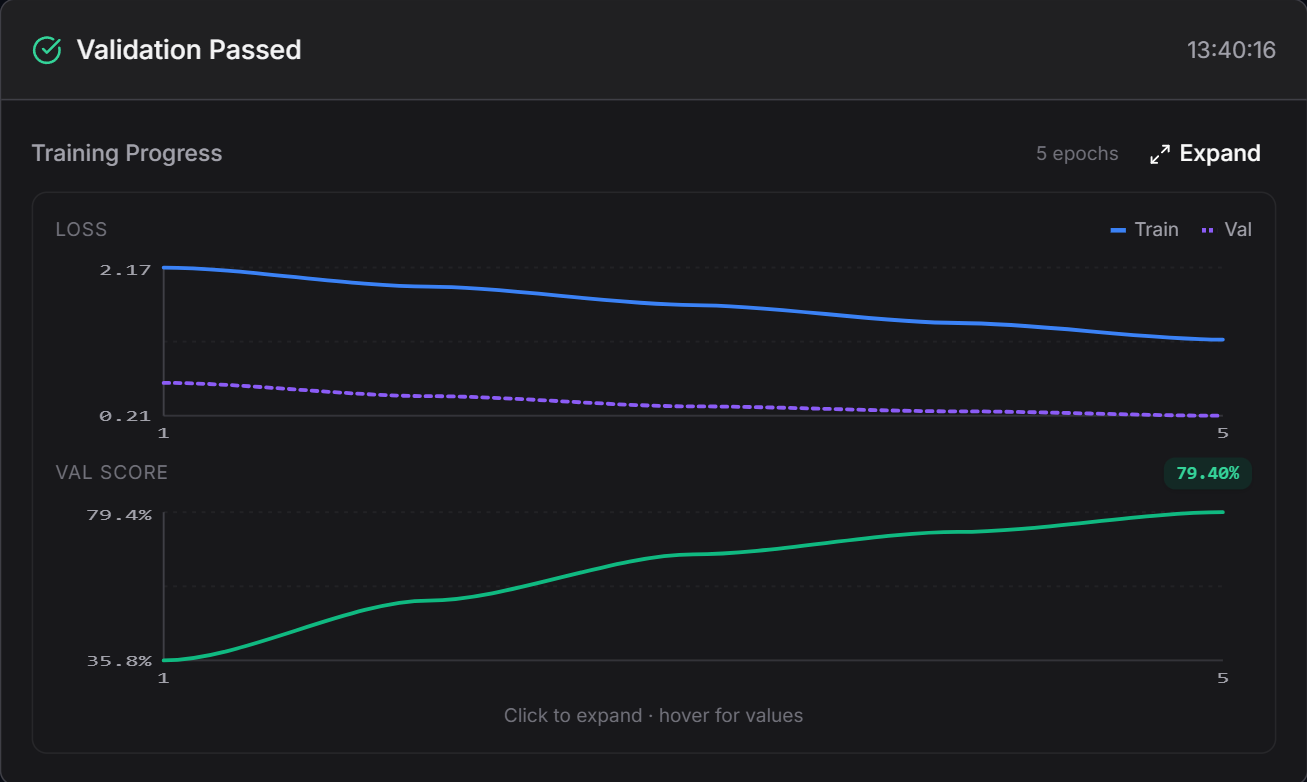

Final Accuracy: 84.3%

### 3. Sigmoid 
Implementing the Sigmoid activation function:
$$f(x)=\frac{1}{1+e^{-x}}$$

Advantages:
- Outputs values between 0 and 1, useful for binary classification
- Smooth and differentiable everywhere
- Simple derivative: $f'(x)=f(x)(1-f(x))$
- Introduces nonlinearity
- Allows probabilistic interpretation of outputs

Disadvantages:
- Suffers from vanishing gradients for large positive or negative inputs
- Not zero-centered, which can slow optimization
- More computationally expensive than ReLU due to the exponential operation
    
Implementation:

In [ ]:
import numpy as np

def activation(x):
    '''
    Apply an activation function element-wise.
    
    Args:
        x: numpy array of any shape (raw neuron outputs)
    
    Returns:
        numpy array of same shape (activated outputs)
    
    Requirements:
        - Must be non-linear (not just returning x)
        - Must work on arrays of any shape
        - Must be deterministic
    '''
    return np.exp(-np.logaddexp(0, -x))

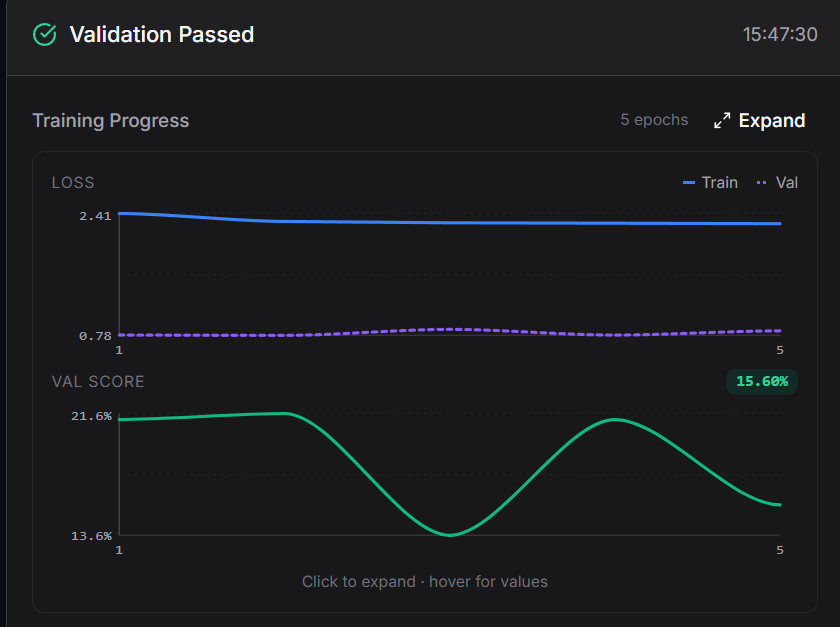

Final accuracy: 19.1% 

# 4. Exponential
I now want to test some other functions that satisfy the general rules of activation functions. Implementing the exponential function:
$$f(x)=1+e^x$$

Advantages:
- Smooth and differentiable everywhere
- Nonlinear, allowing the network to learn complex relationships
- Does not suffer from vanishing gradients for positive inputs
- Large gradients for positive inputs may accelerate learning
- Strictly increasing, preserving the ordering of inputs

Disadvantages:
- Exploding gradients: Exponential growth can cause numerical instability
- Vanishing gradients: For very negative inputs, the derivative approaches zero
- Not zero-centered: outputs are always greater than 1
- Unbounded positive outputs can produce excessively large activations
- Computationally more expensive than ReLU
    
Implementation:

In [ ]:
import numpy as np

def activation(x):
    '''
    Apply an activation function element-wise.
    
    Args:
        x: numpy array of any shape (raw neuron outputs)
    
    Returns:
        numpy array of same shape (activated outputs)
    
    Requirements:
        - Must be non-linear (not just returning x)
        - Must work on arrays of any shape
        - Must be deterministic
    '''
    return np.exp(x - 0.5)

Final accuracy: 87.5%